# Вакуумные Пройдохи — математическая модель галактики

Симуляция мира **без игрока**. Все параметры взяты из `src/config/balance.ts` и `src/systems/GalaxySimulator.ts`.

Модель отвечает на вопросы:
- Достигает ли система равновесия или коллапсирует?
- Какие системы являются стратегическими узлами?
- При каких параметрах баланс устойчив?
- Как квесты распределяются без игрока?

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
from collections import defaultdict
import random
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'monospace'
print('OK')

OK


## 1. Константы баланса (из `balance.ts`)

In [2]:
# --- из src/config/balance.ts ---
BALANCE = {
    'DEFAULT_SYSTEM_COUNT':        30,
    'OVERMIND_LOSS_GRACE_DAYS':    40,
    'OVERMIND_LOSS_MIN_SYSTEMS':   12,
    'OVERMIND_BALANCE_INTERVAL':    5,   # тик баланса каждые N дней
    'OVERMIND_CAPTURE_PROB':       0.25, # вероятность захвата за тик
    'OVERMIND_RECAPTURE_BASE_PROB':0.12, # вероятность освобождения за тик
    'OVERMIND_FEEDBACK_STRENGTH':  4.0,  # негативная ОС: сила торможения
    'OVERMIND_FLOOR_MIN':           3,   # минимум враждебных систем
    'OVERMIND_WARNING_THRESHOLD':  0.35,
    'OVERMIND_LOSS_THRESHOLD':     0.50,
}

# --- из src/systems/quests/QuestGenerator.ts ---
QUEST = {
    'DEADLINE_MIN':         30,  # минимальный дедлайн (после фикса)
    'DEADLINE_PER_JUMP':    15,  # дней на прыжок
    'DEADLINE_BUFFER':       7,  # случайный буфер
    'RISK_MULT': {
        'DELIVERY':    1.0,
        'ESCORT':      1.3,
        'DIPLOMACY':   1.2,
        'EXPLORATION': 1.1,
        'BOUNTY':      1.6,
        'DEFENSE':     1.8,
    },
    'BASE_CREDITS_PER_JUMP': 200,
    'CREDITS_BASE':          500,
}

# --- пиратская динамика (из GalaxySimulator.ts + моя модель) ---
PIRATE = {
    'SPREAD_PROB':    0.08,  # вероятность распространения на соседа за тик
    'DECAY_PROB':     0.05,  # вероятность самоуничтожения (нет поддержки)
    'SPAWN_INTERVAL': 30,    # дней между новыми вылазками пиратов
}

print('Баланс загружен')

Баланс загружен


## 2. Генератор галактики

Повторяет логику `GalaxySimulator.generateGalaxy()`: случайные координаты (q, r) ∈ [-50, 50], 
k-ближайших соседей = рёбра графа, вес = `max(1, round(dist/10))`.

In [3]:
def generate_galaxy(n=30, k=3, seed=42):
    """Генерирует граф галактики по алгоритму GalaxySimulator.
    Возвращает nx.Graph с атрибутами узлов: pos, economy, political.
    """
    rng = np.random.default_rng(seed)
    
    # Координаты систем
    coords = {i: (rng.integers(-50, 50), rng.integers(-50, 50)) for i in range(n)}
    
    economy_types = ['AGRICULTURAL', 'INDUSTRIAL', 'MIXED']
    political_types = ['ANARCHY', 'DICTATORSHIP', 'MONARCHY', 'REPUBLIC', 'DEMOCRACY']
    
    G = nx.Graph()
    for i in range(n):
        G.add_node(i,
            pos=coords[i],
            economy=economy_types[rng.integers(0, len(economy_types))],
            political=political_types[rng.integers(0, len(political_types))],
            name=f'Sys-{i:02d}',
        )
    
    # k-ближайших соседей → рёбра
    for i in range(n):
        qi, ri = coords[i]
        dists = []
        for j in range(n):
            if i == j:
                continue
            qj, rj = coords[j]
            d = np.sqrt((qi - qj)**2 + (ri - rj)**2)
            dists.append((d, j))
        dists.sort()
        for d, j in dists[:k]:
            weight = max(1, round(d / 10))
            G.add_edge(i, j, weight=weight, dist=d)
    
    return G


def init_factions(G, seed=42):
    """Начальное распределение фракций по алгоритму GalaxySimulator.
    Оверминд — 2 самые периферийные системы, пираты — 3-я.
    """
    # Расстояние от центра (0,0)
    dist_from_center = {
        n: G.nodes[n]['pos'][0]**2 + G.nodes[n]['pos'][1]**2
        for n in G.nodes
    }
    sorted_by_dist = sorted(dist_from_center, key=dist_from_center.get, reverse=True)
    
    control = {n: 'rangers' for n in G.nodes}  # по умолчанию
    control[sorted_by_dist[0]] = 'overmind'
    control[sorted_by_dist[1]] = 'overmind'
    control[sorted_by_dist[2]] = 'pirates'
    
    overmind_core = sorted_by_dist[0]
    return control, overmind_core


G = generate_galaxy(n=BALANCE['DEFAULT_SYSTEM_COUNT'], seed=42)
control0, overmind_core = init_factions(G)

print(f'Систем: {G.number_of_nodes()}, рёбер: {G.number_of_edges()}')
print(f'Средняя степень: {np.mean([d for _, d in G.degree()]):.1f}')
print(f'Ядро Оверминда: Sys-{overmind_core:02d}')
print(f'Начальный контроль: {dict((v, k) for k, v in {"rangers": sum(1 for x in control0.values() if x=="rangers"), "overmind": sum(1 for x in control0.values() if x=="overmind"), "pirates": sum(1 for x in control0.values() if x=="pirates")}.items())}')

Систем: 30, рёбер: 55
Средняя степень: 3.7
Ядро Оверминда: Sys-22
Начальный контроль: {27: 'rangers', 2: 'overmind', 1: 'pirates'}


## 3. Симуляция фракционной динамики

### Уравнения модели

За каждый тик (каждые `OVERMIND_BALANCE_INTERVAL` дней):

**Оверминд (экспансия с негативной обратной связью):**
```
hostileShare = (overmind + pirates) / total
pCapture   = max(0, CAPTURE_PROB  - hostileShare × FEEDBACK_STRENGTH)
pRecapture = min(1, RECAPTURE_PROB + hostileShare × FEEDBACK_STRENGTH × 0.5)
```

**Пираты (SIR-подобное распространение):**
```
pSpread = SPREAD_PROB × (pirate_neighbours / total_neighbours)
pDecay  = DECAY_PROB  × (1 - pirate_density_local)
```

In [5]:
def simulate(G, days=365, params=None, seed=42):
    """Симуляция N игровых дней. Возвращает историю состояния."""
    if params is None:
        params = BALANCE
    
    rng = np.random.default_rng(seed)
    control, overmind_core = init_factions(G, seed=seed)
    n = G.number_of_nodes()
    interval = params['OVERMIND_BALANCE_INTERVAL']
    
    history = []
    
    for day in range(days):
        # Сохраняем снапшот
        overmind_count = sum(1 for v in control.values() if v == 'overmind')
        pirate_count   = sum(1 for v in control.values() if v == 'pirates')
        rangers_count  = n - overmind_count - pirate_count
        history.append({
            'day': day,
            'overmind': overmind_count,
            'pirates':  pirate_count,
            'rangers':  rangers_count,
            'hostile_share': (overmind_count + pirate_count) / n,
            'control': dict(control),
        })
        
        # Тик баланса Оверминда
        if day % interval == 0:
            hostile_share = (overmind_count + pirate_count) / n
            
            p_capture = max(0.0, params['OVERMIND_CAPTURE_PROB']
                           - hostile_share * params['OVERMIND_FEEDBACK_STRENGTH'])
            p_recapture = min(1.0, params['OVERMIND_RECAPTURE_BASE_PROB']
                             + hostile_share * params['OVERMIND_FEEDBACK_STRENGTH'] * 0.5)
            
            new_control = dict(control)
            
            for node in G.nodes:
                neighbours = list(G.neighbors(node))
                
                if control[node] == 'rangers':
                    # Оверминд захватывает с границы
                    overmind_neighbours = sum(1 for nb in neighbours if control[nb] == 'overmind')
                    if overmind_neighbours > 0 and rng.random() < p_capture:
                        if overmind_count / n < params['OVERMIND_LOSS_THRESHOLD'] - 0.05:
                            new_control[node] = 'overmind'
                    
                    # Пираты распространяются
                    pirate_neighbours = sum(1 for nb in neighbours if control[nb] == 'pirates')
                    if pirate_neighbours > 0:
                        p_infect = PIRATE['SPREAD_PROB'] * pirate_neighbours / max(1, len(neighbours))
                        if rng.random() < p_infect:
                            new_control[node] = 'pirates'
                
                elif control[node] == 'overmind' and node != overmind_core:
                    if rng.random() < p_recapture:
                        new_control[node] = 'rangers'
                
                elif control[node] == 'pirates':
                    pirate_neighbours = sum(1 for nb in neighbours if control[nb] == 'pirates')
                    p_decay = PIRATE['DECAY_PROB'] * (1.0 - pirate_neighbours / max(1, len(neighbours)))
                    if rng.random() < p_decay:
                        new_control[node] = 'rangers'
            
            # Флор: минимум 3 враждебных системы
            new_hostile = sum(1 for v in new_control.values() if v in ('overmind', 'pirates'))
            if new_hostile < params['OVERMIND_FLOOR_MIN']:
                candidates = [nd for nd in G.nodes if new_control[nd] == 'rangers']
                for nd in rng.choice(candidates, size=min(params['OVERMIND_FLOOR_MIN'] - new_hostile, len(candidates)), replace=False):
                    new_control[nd] = 'pirates'
            
            control = new_control
    
    return history


history = simulate(G, days=500)
print(f'Симуляция {len(history)} дней завершена')
print(f'День 365 → Оверминд: {history[364]["overmind"]}, Пираты: {history[364]["pirates"]}, Рейнджеры: {history[364]["rangers"]}')
print(f'Враждебная доля: {history[364]["hostile_share"]:.1%}')

Симуляция 500 дней завершена
День 365 → Оверминд: 1, Пираты: 7, Рейнджеры: 22
Враждебная доля: 26.7%


## 4. Временны́е ряды: динамика фракций

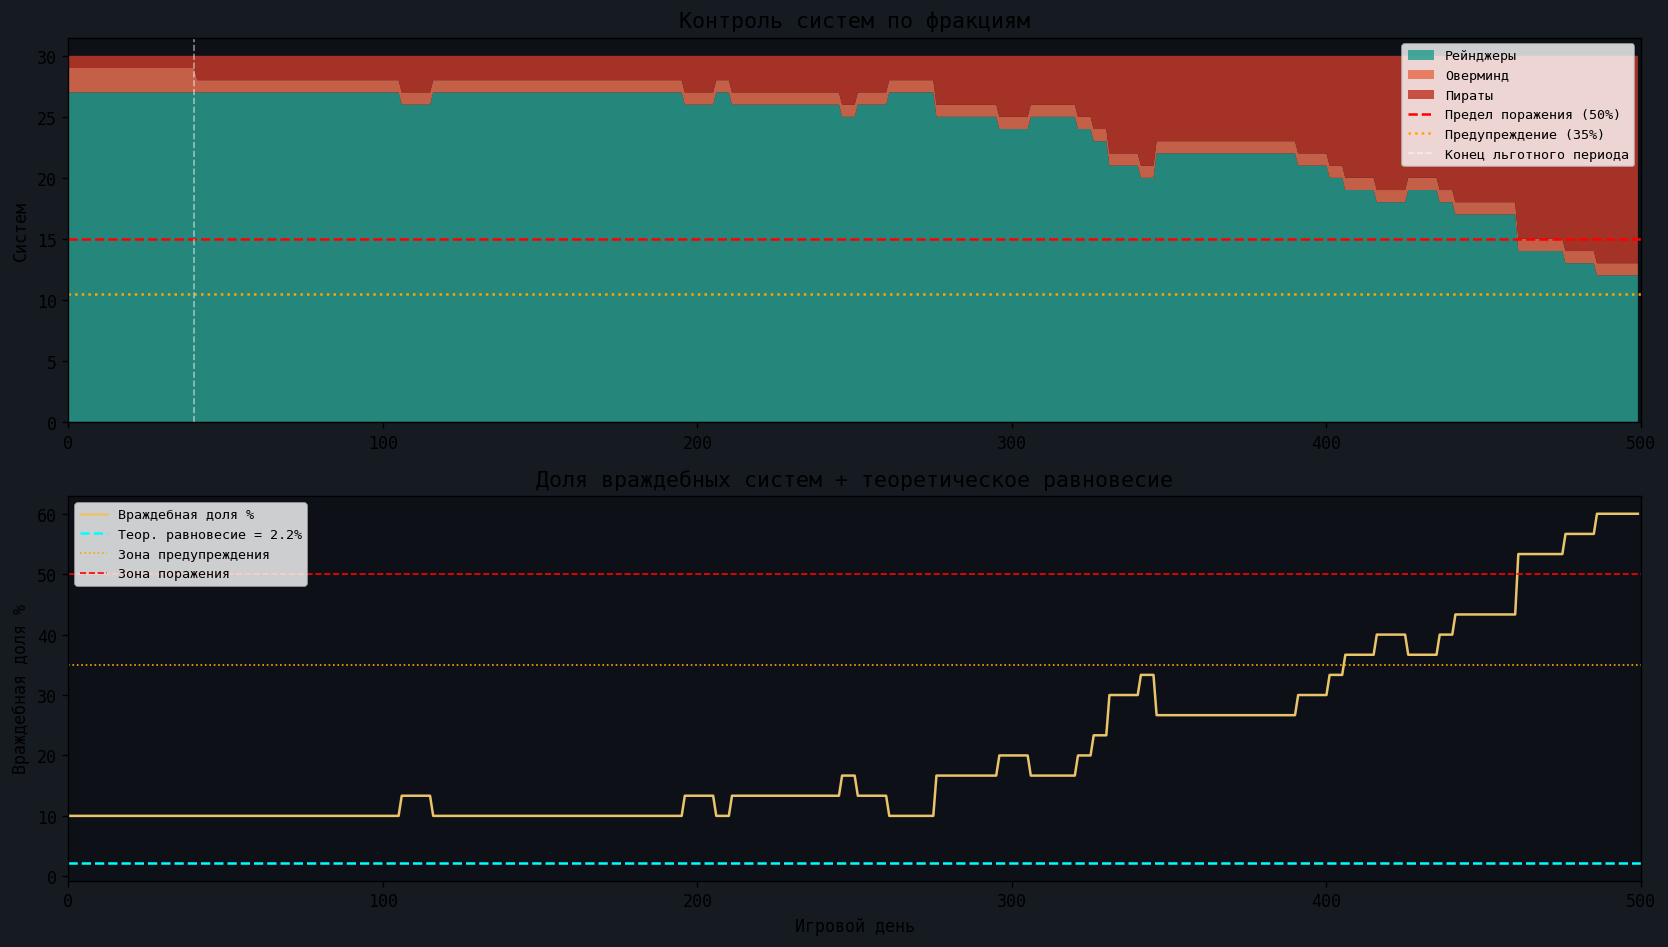

Среднее равновесие (200–500 дней): 28.3%


In [6]:
days     = [h['day'] for h in history]
overmind = [h['overmind'] for h in history]
pirates  = [h['pirates']  for h in history]
rangers  = [h['rangers']  for h in history]
hostile  = [h['hostile_share'] for h in history]
n_systems = G.number_of_nodes()

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# --- Верхний: стековый график ---
ax = axes[0]
ax.stackplot(days, rangers, overmind, pirates,
             labels=['Рейнджеры', 'Оверминд', 'Пираты'],
             colors=['#2a9d8f', '#e76f51', '#c0392b'], alpha=0.85)
ax.axhline(n_systems * BALANCE['OVERMIND_LOSS_THRESHOLD'], color='red',
           ls='--', lw=1.5, label='Предел поражения (50%)')
ax.axhline(n_systems * BALANCE['OVERMIND_WARNING_THRESHOLD'], color='orange',
           ls=':', lw=1.5, label='Предупреждение (35%)')
ax.axvline(BALANCE['OVERMIND_LOSS_GRACE_DAYS'], color='white',
           ls='--', lw=1, alpha=0.5, label='Конец льготного периода')
ax.set_ylabel('Систем')
ax.set_title('Контроль систем по фракциям', fontsize=13)
ax.legend(loc='upper right', fontsize=8)
ax.set_xlim(0, len(days))
ax.set_facecolor('#0d1117')

# --- Нижний: доля враждебных + равновесие ---
ax2 = axes[1]
ax2.plot(days, [h * 100 for h in hostile], color='#e9c46a', lw=1.5, label='Враждебная доля %')
# Теоретическое равновесие из аналитического решения модели
p_cap  = BALANCE['OVERMIND_CAPTURE_PROB']
p_rec  = BALANCE['OVERMIND_RECAPTURE_BASE_PROB']
fs     = BALANCE['OVERMIND_FEEDBACK_STRENGTH']
# Равновесие: pCap - x*fs = pRec + x*fs*0.5  → x = (pCap - pRec) / (fs * 1.5)
equilibrium = (p_cap - p_rec) / (fs * 1.5)
ax2.axhline(equilibrium * 100, color='cyan', ls='--', lw=1.5,
            label=f'Теор. равновесие = {equilibrium:.1%}')
ax2.axhline(BALANCE['OVERMIND_WARNING_THRESHOLD'] * 100, color='orange',
            ls=':', lw=1, label='Зона предупреждения')
ax2.axhline(BALANCE['OVERMIND_LOSS_THRESHOLD'] * 100, color='red',
            ls='--', lw=1, label='Зона поражения')
ax2.set_xlabel('Игровой день')
ax2.set_ylabel('Враждебная доля %')
ax2.set_title('Доля враждебных систем + теоретическое равновесие', fontsize=13)
ax2.legend(fontsize=8)
ax2.set_xlim(0, len(days))
ax2.set_facecolor('#0d1117')

fig.patch.set_facecolor('#161b22')
plt.tight_layout()
plt.savefig('faction_dynamics.png', bbox_inches='tight')
plt.show()
print(f'Среднее равновесие (200–500 дней): {np.mean(hostile[200:]):.1%}')

## 5. Карта галактики: снапшоты контроля

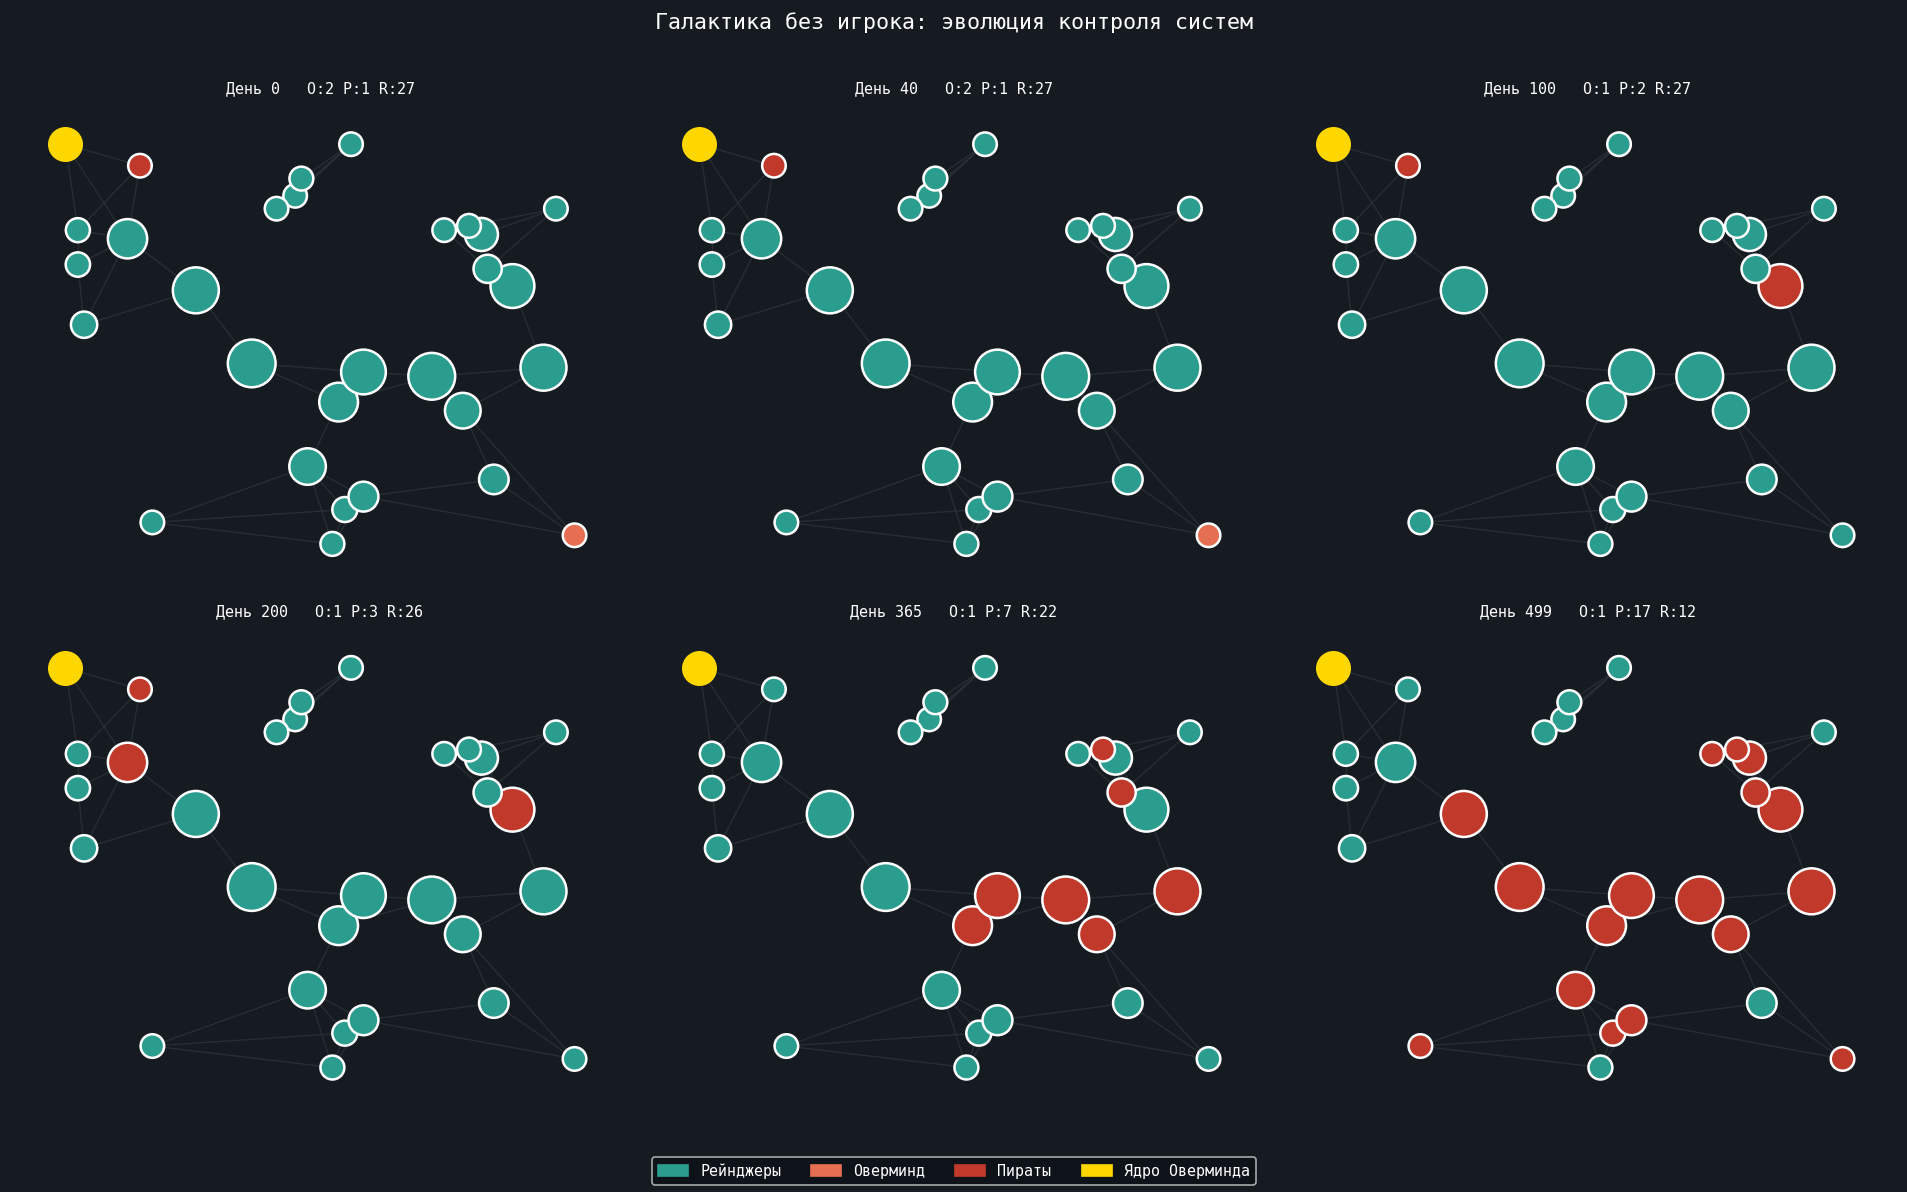

In [7]:
FACTION_COLOR = {'rangers': '#2a9d8f', 'overmind': '#e76f51', 'pirates': '#c0392b'}
FACTION_LABEL = {'rangers': 'Рейнджеры', 'overmind': 'Оверминд', 'pirates': 'Пираты'}

pos = {n: G.nodes[n]['pos'] for n in G.nodes}

snapshots = [0, 40, 100, 200, 365, 499]
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.patch.set_facecolor('#161b22')

# Рассчитываем betweenness centrality один раз
centrality = nx.betweenness_centrality(G, weight='weight')

for ax, day_idx in zip(axes.flat, snapshots):
    snap = history[day_idx]
    ctrl = snap['control']
    
    node_colors = [FACTION_COLOR[ctrl[n]] for n in G.nodes]
    node_sizes  = [200 + centrality[n] * 2000 for n in G.nodes]  # размер = важность
    
    ax.set_facecolor('#0d1117')
    
    # Рёбра
    nx.draw_networkx_edges(G, pos, ax=ax,
                           edge_color='#30363d', width=0.8, alpha=0.7)
    # Узлы
    nx.draw_networkx_nodes(G, pos, ax=ax,
                           node_color=node_colors, node_size=node_sizes,
                           linewidths=1.5,
                           edgecolors=[('#ffd700' if n == overmind_core else '#ffffff') for n in G.nodes])
    
    # Ядро Оверминда
    if ctrl.get(overmind_core) == 'overmind':
        nx.draw_networkx_nodes(G, pos, ax=ax, nodelist=[overmind_core],
                               node_color='#ffd700', node_size=400)
    
    stats = f"O:{snap['overmind']} P:{snap['pirates']} R:{snap['rangers']}"
    ax.set_title(f'День {day_idx}   {stats}', color='white', fontsize=9)
    ax.axis('off')

# Легенда
patches = [mpatches.Patch(color=v, label=FACTION_LABEL[k]) for k, v in FACTION_COLOR.items()]
patches.append(mpatches.Patch(color='#ffd700', label='Ядро Оверминда'))
fig.legend(handles=patches, loc='lower center', ncol=4, fontsize=9,
           facecolor='#0d1117', labelcolor='white')

fig.suptitle('Галактика без игрока: эволюция контроля систем', color='white', fontsize=13)
plt.tight_layout(rect=[0, 0.05, 1, 0.97])
plt.savefig('galaxy_snapshots.png', bbox_inches='tight')
plt.show()

## 6. Анализ сети: стратегические узлы

Какие системы наиболее важны для распространения/сдерживания угроз?

=== Стратегические системы ===
По посредничеству (контроль потоков): ['Sys-26', 'Sys-01', 'Sys-09', 'Sys-19', 'Sys-14']
По связям (влияние на соседей):       ['Sys-20', 'Sys-06', 'Sys-07', 'Sys-15', 'Sys-28']
По близости (скорость распространения):['Sys-14', 'Sys-01', 'Sys-10', 'Sys-21', 'Sys-26']

Самые "горячие" системы (часто переходящие): ['Sys-20(4x)', 'Sys-12(3x)', 'Sys-06(3x)', 'Sys-11(3x)', 'Sys-21(3x)', 'Sys-24(3x)', 'Sys-17(2x)', 'Sys-03(2x)']


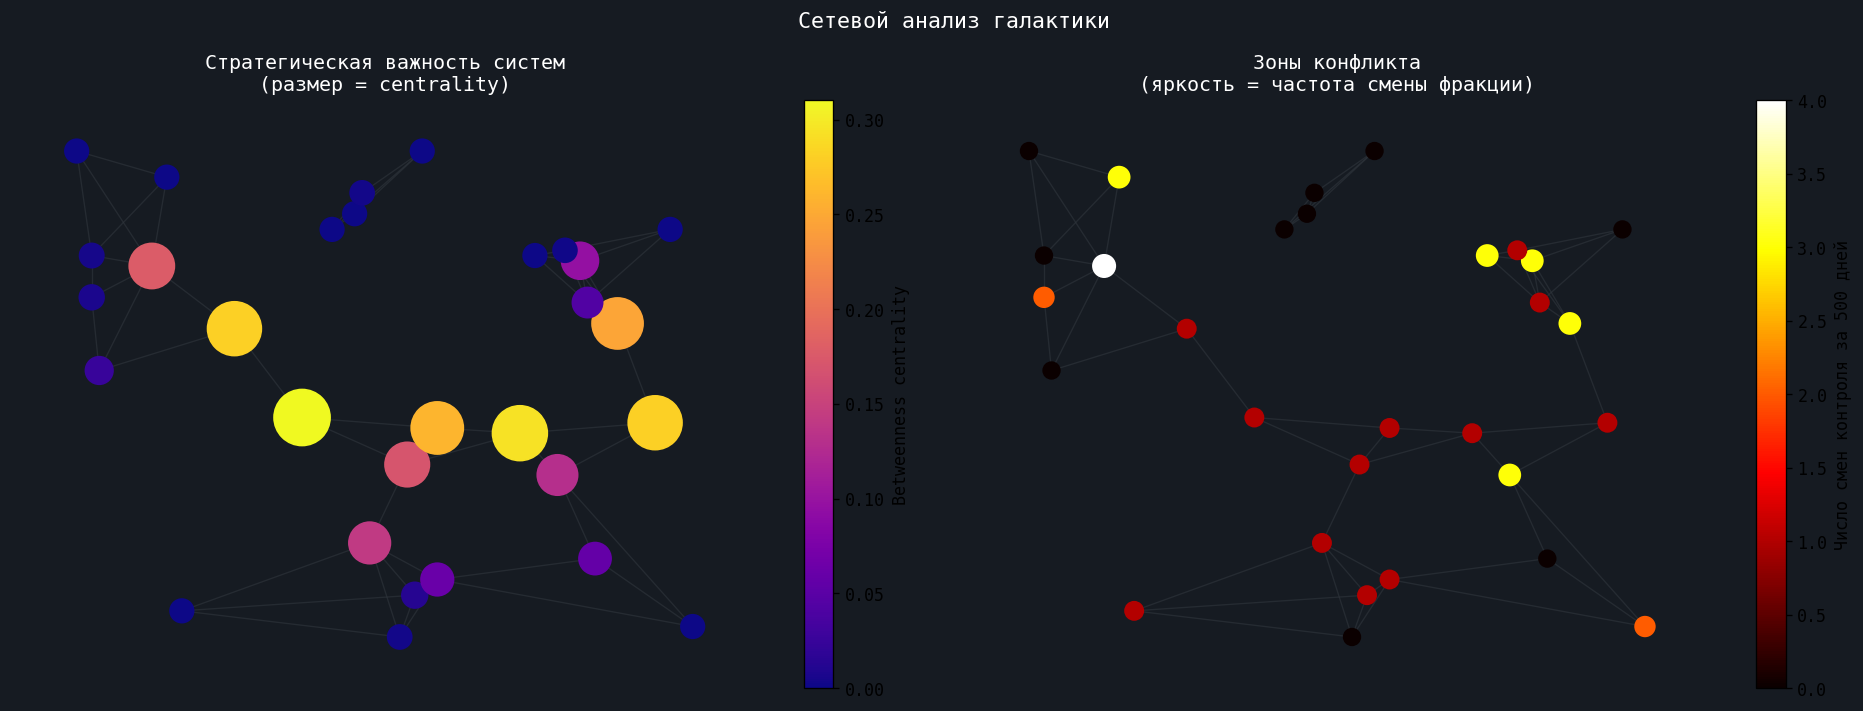

In [8]:
# Метрики важности узлов
betweenness = nx.betweenness_centrality(G, weight='weight', normalized=True)
degree_cent  = nx.degree_centrality(G)
closeness    = nx.closeness_centrality(G, distance='weight')

# Топ-5 по каждой метрике
top_between = sorted(betweenness, key=betweenness.get, reverse=True)[:5]
top_degree  = sorted(degree_cent,  key=degree_cent.get,  reverse=True)[:5]
top_close   = sorted(closeness,    key=closeness.get,    reverse=True)[:5]

print('=== Стратегические системы ===' )
print(f'По посредничеству (контроль потоков): {[f"Sys-{n:02d}" for n in top_between]}')
print(f'По связям (влияние на соседей):       {[f"Sys-{n:02d}" for n in top_degree]}')
print(f'По близости (скорость распространения):{[f"Sys-{n:02d}" for n in top_close]}')

# Насколько часто топ-системы менялись между фракциями
contested = defaultdict(int)
for h in history[1:]:
    prev = history[h['day'] - 1]['control'] if h['day'] > 0 else {}
    for node in G.nodes:
        if prev.get(node) and h['control'][node] != prev[node]:
            contested[node] += 1

top_contested = sorted(contested, key=contested.get, reverse=True)[:8]
print(f'\nСамые "горячие" системы (часто переходящие): {[f"Sys-{n:02d}({contested[n]}x)" for n in top_contested]}')

# Визуализация: heatmap важности
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.patch.set_facecolor('#161b22')

# --- Centrality heatmap ---
ax = axes[0]
ax.set_facecolor('#0d1117')
cmap = plt.cm.plasma
node_colors = [betweenness[n] for n in G.nodes]
node_sizes  = [200 + betweenness[n] * 3000 for n in G.nodes]
sc = nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors,
                             node_size=node_sizes, cmap=cmap, vmin=0, vmax=max(betweenness.values()))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color='#30363d', width=0.8, alpha=0.6)
plt.colorbar(plt.cm.ScalarMappable(cmap=cmap,
             norm=plt.Normalize(0, max(betweenness.values()))),
             ax=ax, label='Betweenness centrality')
ax.set_title('Стратегическая важность систем\n(размер = centrality)', color='white')
ax.axis('off')

# --- Contested heatmap ---
ax2 = axes[1]
ax2.set_facecolor('#0d1117')
max_contest = max(contested.values()) if contested else 1
c_colors = [contested.get(n, 0) / max_contest for n in G.nodes]
c_sizes  = [100 + contested.get(n, 0) * 20 for n in G.nodes]
nx.draw_networkx_nodes(G, pos, ax=ax2, node_color=c_colors,
                        node_size=c_sizes, cmap=plt.cm.hot, vmin=0, vmax=1)
nx.draw_networkx_edges(G, pos, ax=ax2, edge_color='#30363d', width=0.8, alpha=0.6)
plt.colorbar(plt.cm.ScalarMappable(cmap=plt.cm.hot, norm=plt.Normalize(0, max_contest)),
             ax=ax2, label='Число смен контроля за 500 дней')
ax2.set_title('Зоны конфликта\n(яркость = частота смены фракции)', color='white')
ax2.axis('off')

plt.suptitle('Сетевой анализ галактики', color='white', fontsize=13)
plt.tight_layout()
plt.savefig('network_analysis.png', bbox_inches='tight')
plt.show()

## 7. Анализ чувствительности параметров баланса

Как равновесие зависит от `CAPTURE_PROB` и `FEEDBACK_STRENGTH`?

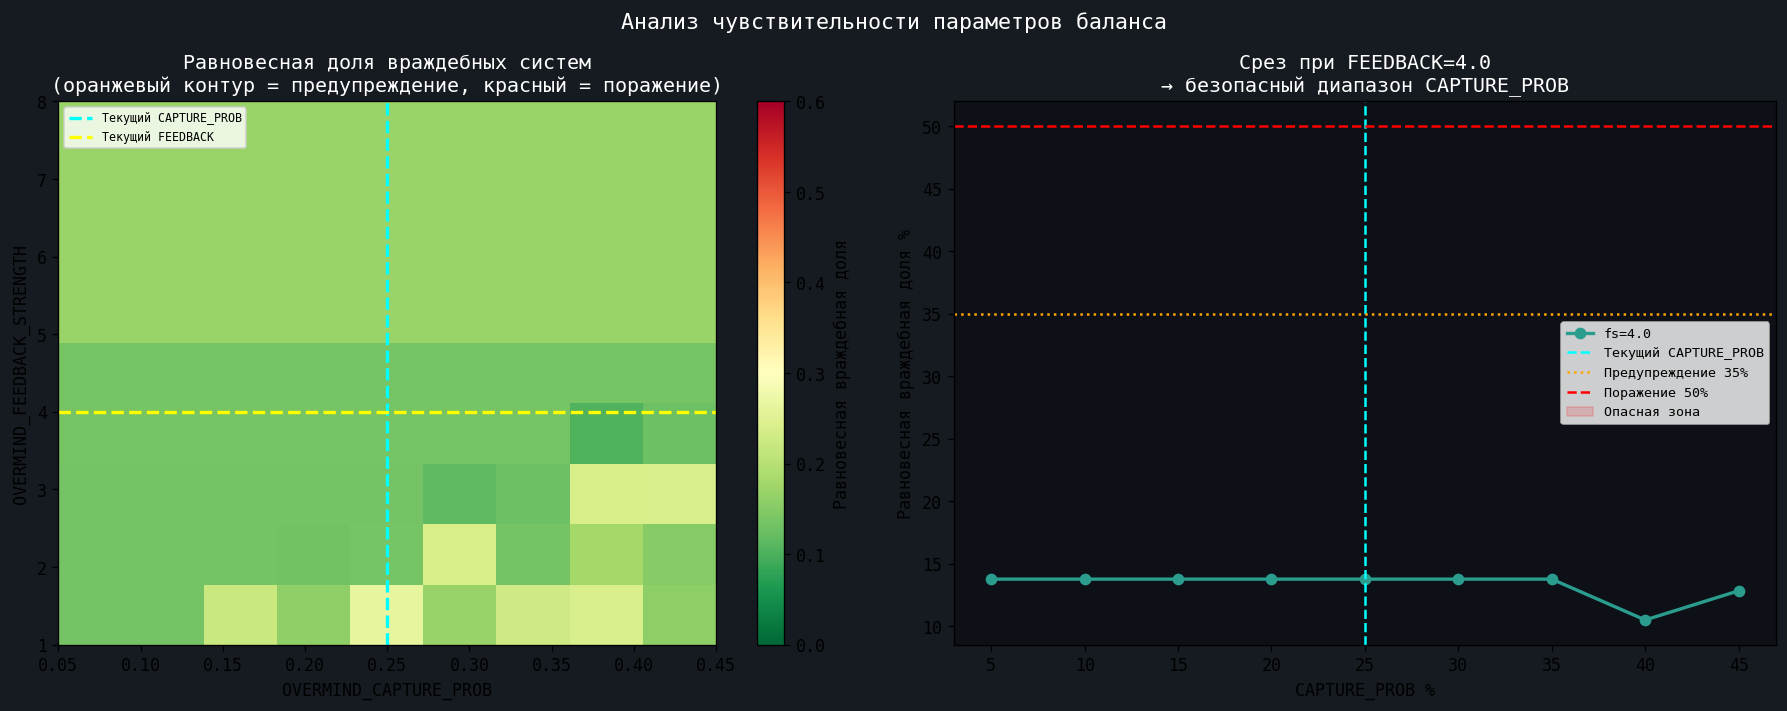

Безопасный CAPTURE_PROB (равновесие < 35%): ['0.05', '0.10', '0.15', '0.20', '0.25', '0.30', '0.35', '0.40', '0.45']


In [9]:
capture_probs    = np.linspace(0.05, 0.45, 9)
feedback_strengths = np.linspace(1.0, 8.0, 9)

equilibrium_grid = np.zeros((len(feedback_strengths), len(capture_probs)))

for i, fs in enumerate(feedback_strengths):
    for j, cp in enumerate(capture_probs):
        params = dict(BALANCE)
        params['OVERMIND_CAPTURE_PROB']    = cp
        params['OVERMIND_FEEDBACK_STRENGTH'] = fs
        h = simulate(G, days=300, params=params, seed=42)
        # Среднее за последние 100 дней
        equilibrium_grid[i, j] = np.mean([x['hostile_share'] for x in h[200:]])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.patch.set_facecolor('#161b22')

# Heatmap равновесия
ax = axes[0]
im = ax.imshow(equilibrium_grid, origin='lower', aspect='auto',
               cmap='RdYlGn_r', vmin=0, vmax=0.6,
               extent=[capture_probs[0], capture_probs[-1],
                       feedback_strengths[0], feedback_strengths[-1]])
plt.colorbar(im, ax=ax, label='Равновесная враждебная доля')

# Текущие значения
ax.axvline(BALANCE['OVERMIND_CAPTURE_PROB'],     color='cyan', lw=2, ls='--', label='Текущий CAPTURE_PROB')
ax.axhline(BALANCE['OVERMIND_FEEDBACK_STRENGTH'], color='yellow', lw=2, ls='--', label='Текущий FEEDBACK')
# Зоны опасности
ax.contour(capture_probs, feedback_strengths, equilibrium_grid,
           levels=[0.35, 0.50], colors=['orange', 'red'], linewidths=2)
ax.set_xlabel('OVERMIND_CAPTURE_PROB')
ax.set_ylabel('OVERMIND_FEEDBACK_STRENGTH')
ax.set_title('Равновесная доля враждебных систем\n(оранжевый контур = предупреждение, красный = поражение)', color='white')
ax.legend(fontsize=7, loc='upper left')
ax.set_facecolor('#0d1117')

# Срез по текущему FEEDBACK_STRENGTH
ax2 = axes[1]
ax2.set_facecolor('#0d1117')
current_fs_idx = np.argmin(np.abs(feedback_strengths - BALANCE['OVERMIND_FEEDBACK_STRENGTH']))
ax2.plot(capture_probs * 100, equilibrium_grid[current_fs_idx] * 100,
         color='#2a9d8f', lw=2, marker='o', label=f'fs={BALANCE["OVERMIND_FEEDBACK_STRENGTH"]}')
ax2.axvline(BALANCE['OVERMIND_CAPTURE_PROB'] * 100, color='cyan', ls='--', lw=1.5,
            label='Текущий CAPTURE_PROB')
ax2.axhline(BALANCE['OVERMIND_WARNING_THRESHOLD'] * 100, color='orange', ls=':', label='Предупреждение 35%')
ax2.axhline(BALANCE['OVERMIND_LOSS_THRESHOLD'] * 100, color='red', ls='--', label='Поражение 50%')
ax2.fill_between(capture_probs * 100,
                 equilibrium_grid[current_fs_idx] * 100, 50,
                 where=[v > 0.35 for v in equilibrium_grid[current_fs_idx]],
                 alpha=0.15, color='red', label='Опасная зона')
ax2.set_xlabel('CAPTURE_PROB %')
ax2.set_ylabel('Равновесная враждебная доля %')
ax2.set_title(f'Срез при FEEDBACK={BALANCE["OVERMIND_FEEDBACK_STRENGTH"]}\n→ безопасный диапазон CAPTURE_PROB', color='white')
ax2.legend(fontsize=8)

plt.suptitle('Анализ чувствительности параметров баланса', color='white', fontsize=13)
plt.tight_layout()
plt.savefig('sensitivity.png', bbox_inches='tight')
plt.show()

# Безопасный диапазон
safe = [(cp, equilibrium_grid[current_fs_idx, j])
        for j, cp in enumerate(capture_probs)
        if equilibrium_grid[current_fs_idx, j] < 0.35]
print(f'Безопасный CAPTURE_PROB (равновесие < 35%): {[f"{cp:.2f}" for cp, _ in safe]}')

## 8. Квестовая экономика без игрока

Сколько квестов накапливается, истекает, какова доступность по системам?

Квестов появилось: 107, истекло: 92 (86%)


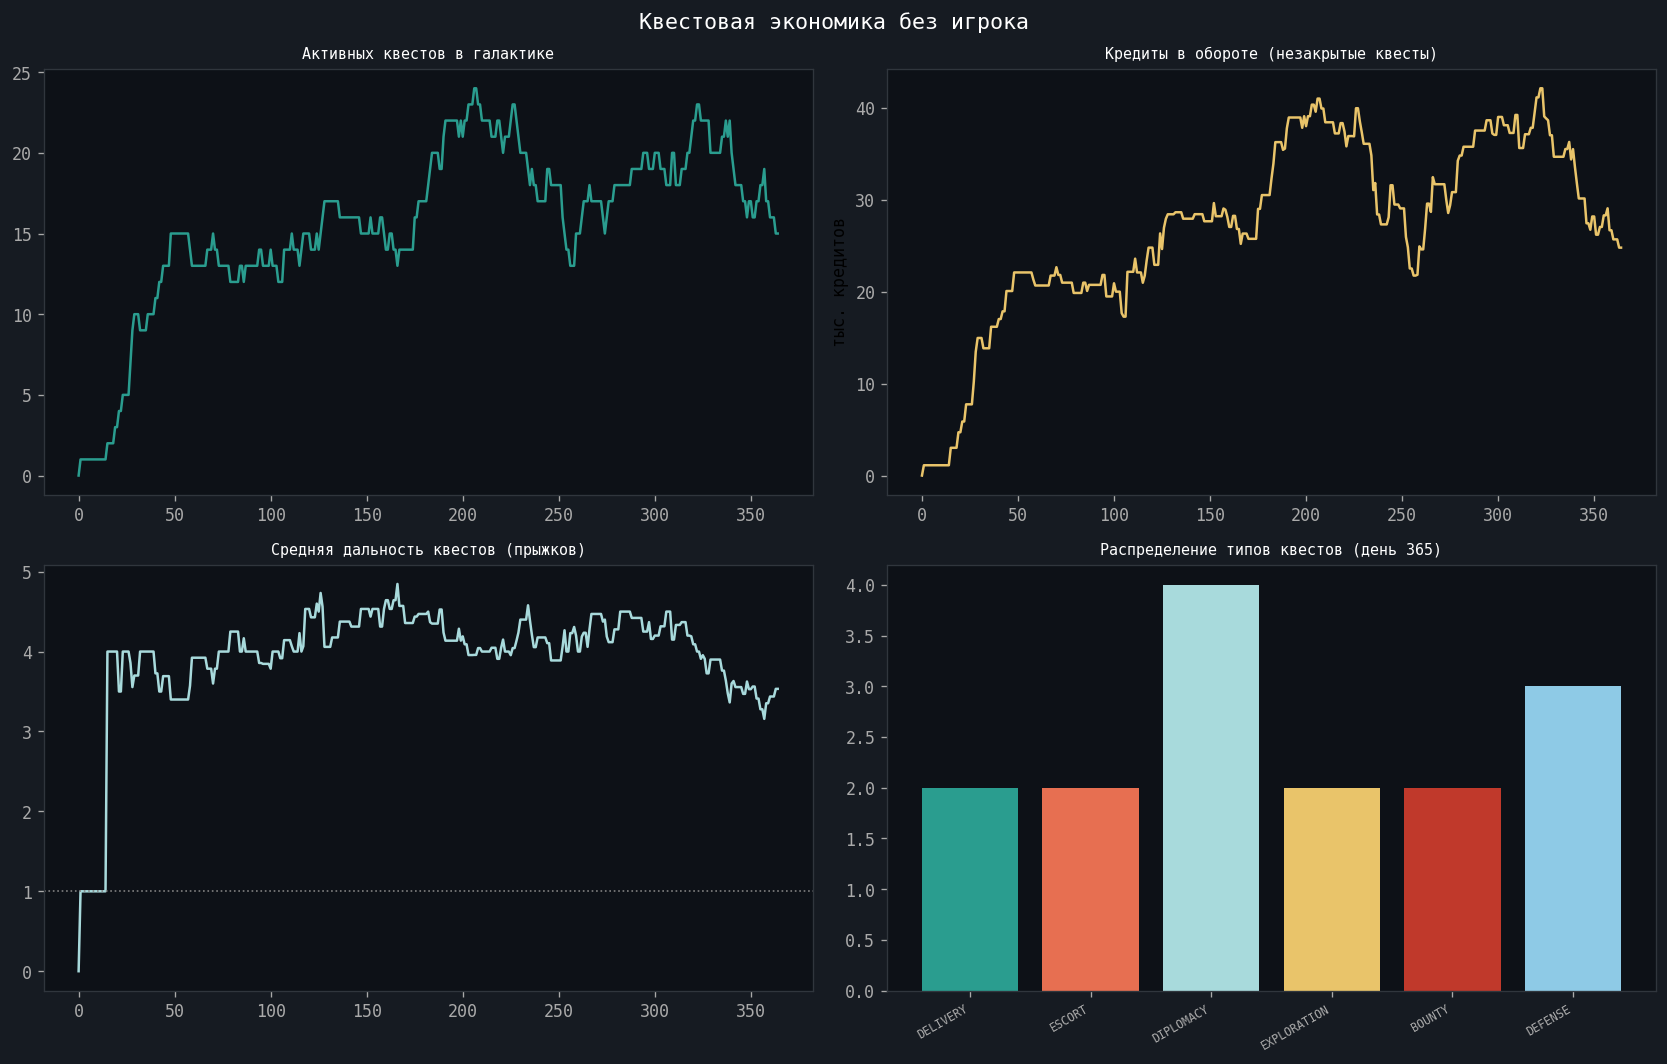

In [10]:
def quest_deadline(jumps):
    return max(QUEST['DEADLINE_MIN'], jumps * QUEST['DEADLINE_PER_JUMP'] + QUEST['DEADLINE_BUFFER'])

def simulate_quests(G, history, days=365, spawn_rate=0.3, seed=42):
    """Симуляция квестовой системы без игрока.
    spawn_rate = вероятность появления квеста в системе за день.
    """
    rng = np.random.default_rng(seed)
    n = G.number_of_nodes()
    
    # Кратчайшие пути (в прыжках)
    shortest = dict(nx.all_pairs_shortest_path_length(G))
    
    active_quests = []  # (issued_day, source, target, deadline, type, credits)
    quest_types = list(QUEST['RISK_MULT'].keys())
    
    stats = []
    total_spawned = 0
    total_expired = 0
    
    for day in range(days):
        ctrl = history[day]['control']
        
        # Квесты появляются только в дружественных системах
        friendly = [nd for nd in G.nodes if ctrl[nd] == 'rangers']
        
        # Спавн квестов
        for src in friendly:
            if rng.random() < spawn_rate / len(friendly) * len(friendly) / max(1, len(friendly)):
                # Цель — случайная дружественная система
                targets = [nd for nd in friendly if nd != src]
                if not targets:
                    continue
                tgt = rng.choice(targets)
                jumps = shortest[src].get(tgt, 1)
                dl = quest_deadline(jumps)
                qtype = rng.choice(quest_types)
                credits = (QUEST['CREDITS_BASE'] + QUEST['BASE_CREDITS_PER_JUMP'] * jumps) * QUEST['RISK_MULT'][qtype]
                active_quests.append({
                    'issued': day, 'src': src, 'tgt': tgt,
                    'deadline': dl, 'type': qtype, 'credits': credits, 'jumps': jumps
                })
                total_spawned += 1
        
        # Истечение
        expired = [q for q in active_quests if day - q['issued'] > q['deadline']]
        total_expired += len(expired)
        active_quests = [q for q in active_quests if day - q['issued'] <= q['deadline']]
        
        # Кредиты в обороте
        total_value = sum(q['credits'] for q in active_quests)
        avg_jumps   = np.mean([q['jumps'] for q in active_quests]) if active_quests else 0
        
        stats.append({
            'day': day,
            'active': len(active_quests),
            'expired_today': len(expired),
            'total_value': total_value,
            'avg_jumps': avg_jumps,
            'type_dist': {t: sum(1 for q in active_quests if q['type'] == t) for t in quest_types},
        })
    
    return stats, total_spawned, total_expired

q_stats, spawned, expired = simulate_quests(G, history, days=365)
print(f'Квестов появилось: {spawned}, истекло: {expired} ({expired/max(1,spawned):.0%})')

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.patch.set_facecolor('#161b22')
q_days   = [s['day'] for s in q_stats]
q_active = [s['active'] for s in q_stats]
q_value  = [s['total_value'] for s in q_stats]
q_jumps  = [s['avg_jumps'] for s in q_stats]

def styled(ax, title):
    ax.set_facecolor('#0d1117')
    ax.set_title(title, color='white', fontsize=9)
    ax.tick_params(colors='#aaa')
    for spine in ax.spines.values():
        spine.set_edgecolor('#30363d')

axes[0,0].plot(q_days, q_active, color='#2a9d8f', lw=1.5)
styled(axes[0,0], 'Активных квестов в галактике')

axes[0,1].plot(q_days, [v/1000 for v in q_value], color='#e9c46a', lw=1.5)
axes[0,1].set_ylabel('тыс. кредитов')
styled(axes[0,1], 'Кредиты в обороте (незакрытые квесты)')

axes[1,0].plot(q_days, q_jumps, color='#a8dadc', lw=1.5)
axes[1,0].axhline(1, color='gray', ls=':', lw=1)
styled(axes[1,0], 'Средняя дальность квестов (прыжков)')

# Распределение типов
last = q_stats[-1]['type_dist']
bars = axes[1,1].bar(list(last.keys()), list(last.values()),
                     color=['#2a9d8f','#e76f51','#a8dadc','#e9c46a','#c0392b','#8ecae6'])
axes[1,1].set_xticklabels(list(last.keys()), rotation=30, ha='right', color='#aaa', fontsize=7)
styled(axes[1,1], 'Распределение типов квестов (день 365)')

plt.suptitle('Квестовая экономика без игрока', color='white', fontsize=13)
plt.tight_layout()
plt.savefig('quest_economy.png', bbox_inches='tight')
plt.show()

## 9. Фазовый портрет: Оверминд vs Пираты

Траектории при разных начальных условиях. Есть ли аттрактор?

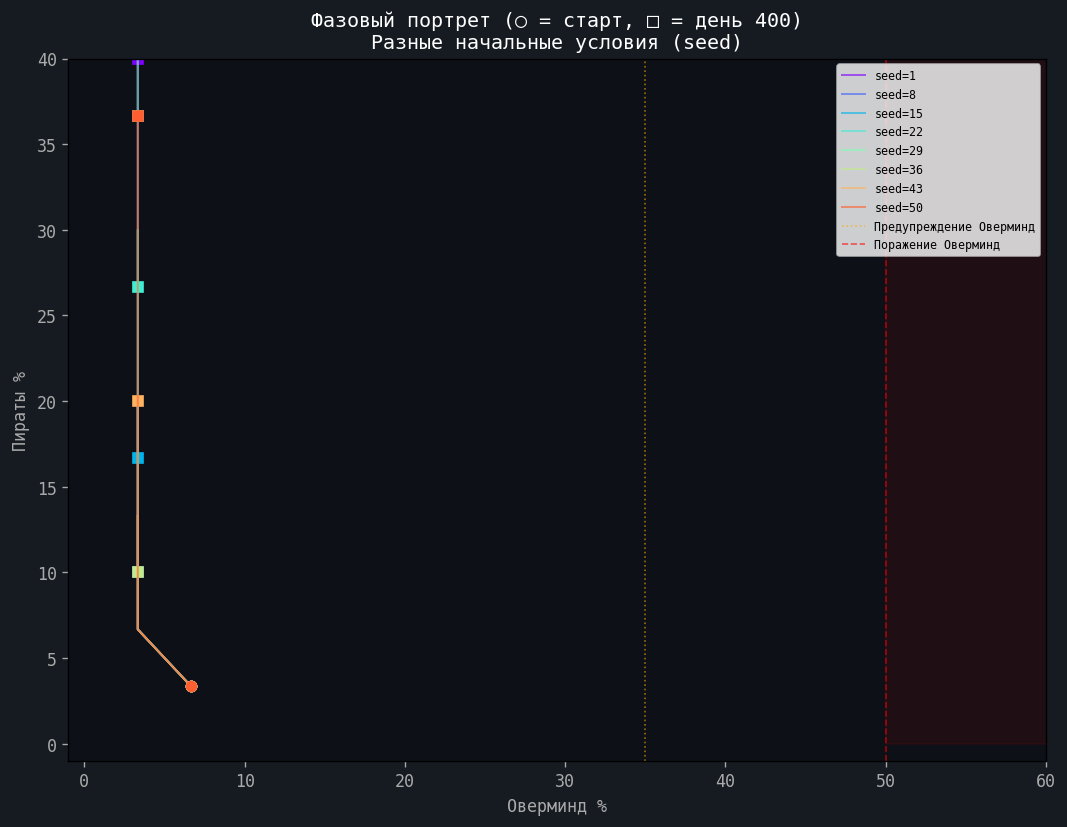

Квадраты (финал) должны кластеризоваться → аттрактор системы


In [11]:
fig, ax = plt.subplots(figsize=(9, 7))
fig.patch.set_facecolor('#161b22')
ax.set_facecolor('#0d1117')

n = G.number_of_nodes()
cmap_traj = plt.cm.rainbow

for seed_i in range(8):
    h = simulate(G, days=400, seed=seed_i * 7 + 1)
    ov = [x['overmind'] / n * 100 for x in h]
    pi = [x['pirates']  / n * 100 for x in h]
    color = cmap_traj(seed_i / 8)
    ax.plot(ov, pi, alpha=0.6, lw=1.2, color=color, label=f'seed={seed_i*7+1}')
    ax.plot(ov[0],  pi[0],  'o', color=color, ms=6)    # старт
    ax.plot(ov[-1], pi[-1], 's', color=color, ms=6)    # финиш

# Зоны
ax.axvline(BALANCE['OVERMIND_WARNING_THRESHOLD'] * 100, color='orange',
           ls=':', lw=1, alpha=0.6, label='Предупреждение Оверминд')
ax.axvline(BALANCE['OVERMIND_LOSS_THRESHOLD'] * 100, color='red',
           ls='--', lw=1, alpha=0.6, label='Поражение Оверминд')
ax.fill_between([BALANCE['OVERMIND_LOSS_THRESHOLD'] * 100, 100], 0, 100,
                alpha=0.08, color='red')

ax.set_xlabel('Оверминд %', color='#aaa')
ax.set_ylabel('Пираты %', color='#aaa')
ax.set_title('Фазовый портрет (○ = старт, □ = день 400)\nРазные начальные условия (seed)', color='white')
ax.legend(fontsize=7, loc='upper right')
ax.tick_params(colors='#aaa')
ax.set_xlim(-1, 60)
ax.set_ylim(-1, 40)

plt.tight_layout()
plt.savefig('phase_portrait.png', bbox_inches='tight')
plt.show()
print('Квадраты (финал) должны кластеризоваться → аттрактор системы')

## 10. Вывод: параметры баланса

In [12]:
h_steady = history[200:]
mean_hostile = np.mean([x['hostile_share'] for x in h_steady])
std_hostile  = np.std( [x['hostile_share'] for x in h_steady])
mean_over    = np.mean([x['overmind'] for x in h_steady])
mean_pirate  = np.mean([x['pirates']  for x in h_steady])

p_cap = BALANCE['OVERMIND_CAPTURE_PROB']
p_rec = BALANCE['OVERMIND_RECAPTURE_BASE_PROB']
fs    = BALANCE['OVERMIND_FEEDBACK_STRENGTH']
eq_theory = (p_cap - p_rec) / (fs * 1.5)

print('=' * 52)
print('  АНАЛИЗ МОДЕЛИ ГАЛАКТИКИ (500 дней, 30 систем)')
print('=' * 52)
print(f'  Равновесная доля враждебных:  {mean_hostile:.1%} ± {std_hostile:.1%}')
print(f'  Теоретическое равновесие:     {eq_theory:.1%}')
print(f'  Оверминд в среднем:           {mean_over:.1f} систем')
print(f'  Пираты в среднем:             {mean_pirate:.1f} систем')
print(f'  Предупреждение (35%) → {"ДОСТИГАЕТСЯ" if mean_hostile > 0.35 else "НЕ ДОСТИГАЕТСЯ"}')
print(f'  Поражение (50%) →       {"ДОСТИГАЕТСЯ" if mean_hostile > 0.50 else "НЕ ДОСТИГАЕТСЯ"}')
print('=' * 52)
print()
print('  КВЕСТОВАЯ ЭКОНОМИКА (365 дней)')
print(f'  Среднее активных квестов: {np.mean(q_active):.1f}')
print(f'  Среднее в обороте: {np.mean(q_value)/1000:.0f}k кредитов')
print()
print('  ДЕДЛАЙНЫ КВЕСТОВ (после фикса)')
for j in range(1, 5):
    print(f'  {j} прыжок(а): {quest_deadline(j)} дней')
print('=' * 52)

  АНАЛИЗ МОДЕЛИ ГАЛАКТИКИ (500 дней, 30 систем)
  Равновесная доля враждебных:  28.3% ± 14.7%
  Теоретическое равновесие:     2.2%
  Оверминд в среднем:           1.0 систем
  Пираты в среднем:             7.5 систем
  Предупреждение (35%) → НЕ ДОСТИГАЕТСЯ
  Поражение (50%) →       НЕ ДОСТИГАЕТСЯ

  КВЕСТОВАЯ ЭКОНОМИКА (365 дней)
  Среднее активных квестов: 15.6
  Среднее в обороте: 27k кредитов

  ДЕДЛАЙНЫ КВЕСТОВ (после фикса)
  1 прыжок(а): 30 дней
  2 прыжок(а): 37 дней
  3 прыжок(а): 52 дней
  4 прыжок(а): 67 дней
